# Predicción de Diabetes Mediante Técnicas de Minería de Datos Aplicadas a Indicadores Clínicos
## Segundo avance: EDA, modelado y resultados preliminares

**Integrantes:** Fabián López, Jonathan Cárdenas, Luis Cárdenas

**Tipo de proyecto:** Clasificación (aprendizaje supervisado)

**Pregunta que se busca responder:** ¿Es posible predecir si una paciente presenta diabetes a partir de indicadores clínicos sencillos (glucosa, presión arterial, IMC, edad, etc.), y qué modelo de clasificación ofrece el mejor equilibrio entre capacidad de detección de casos positivos e interpretabilidad?

**Dataset:** *Pima Indians Diabetes Database* — NIDDK (Smith et al., 1988). Enlace de descarga: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database.
Contiene 768 registros de mujeres de al menos 21 años de origen indígena Pima, con 8 variables predictoras y la variable objetivo.

**Variable objetivo:** `outcome` (1 = diabetes, 0 = no diabetes).

### Continuidad con el primer avance y cambios realizados
Este notebook continúa el del primer avance: se conservan la carga, la descripción, la revisión de calidad y la detección de valores atípicos. Los cambios frente al primer avance son:

| # | Cambio | Justificación |
|---|---|---|
| 1 | La **imputación por mediana ya no se hace sobre todo el dataset**. Los ceros clínicamente imposibles se dejan como `NaN` y la imputación se ejecuta **dentro de un `Pipeline`**, ajustada solo con los datos de entrenamiento. | En el primer avance la mediana se calculaba con los 768 registros. Si luego se divide en entrenamiento/prueba, la información del conjunto de prueba "se filtra" al entrenamiento (fuga de información) y las métricas quedan optimistas. Es una corrección de la limpieza. |
| 2 | El archivo `diabetes_limpio.csv` del primer avance (con medianas ya imputadas) **no se usa para modelar**. | Es consecuencia del cambio 1. |
| 3 | No se cambió el dataset, la pregunta ni la variable objetivo. | — |

### Correspondencia entre este notebook y el informe
Las figuras del informe conservan la numeración de este notebook (Figuras 1 a 11). Las tablas del informe se generan con las salidas de estas celdas:

| Tabla del informe | Dónde se genera en el notebook |
|---|---|
| Tabla 1. Valores no registrados | Sección 3.4 |
| Tabla 2. Promedios por grupo | Sección 4.3 |
| Tabla 3. Validación cruzada (media ± desviación) | Sección 5.3 |
| Tabla 4. Métricas en prueba | Sección 5.4 |
| Tabla 5. Matrices de confusión | Sección 6.1 |
| Tabla 6. Métricas por clase en prueba | Sección 6.2 |
| Tabla 7. Accuracy entrenamiento / validación cruzada / prueba | Secciones 5.3 y 5.4 (Figura 9) |

**Para reproducirlo:** colocar `diabetes.csv` en la misma carpeta del notebook y ejecutar todas las celdas en orden (`Kernel > Restart & Run All`). Se usan `random_state=42`; con otras versiones de scikit-learn pueden cambiar algunos decimales.

## 1. Importación de librerías

In [1]:
import json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay, roc_curve)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
os.makedirs("figs", exist_ok=True)
resultados = {}   # se guarda en results.json para que el informe use exactamente estas cifras

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(f"figs/{nombre}.png", dpi=150, bbox_inches="tight")
    plt.show()

print("Librerías importadas correctamente.")

Librerías importadas correctamente.


## 2. Descripción y carga del dataset (del primer avance)

**Nombre:** Pima Indians Diabetes Database · **Fuente:** NIDDK (Smith et al., 1988), Kaggle · **Filas/columnas iniciales:** 768 × 9.

| Variable | Descripción |
|---|---|
| `Pregnancies` | Número de embarazos |
| `Glucose` | Concentración de glucosa en plasma (prueba de tolerancia oral) |
| `BloodPressure` | Presión arterial diastólica (mm Hg) |
| `SkinThickness` | Espesor del pliegue cutáneo del tríceps (mm) |
| `Insulin` | Insulina sérica a las 2 horas (mu U/ml) |
| `BMI` | Índice de masa corporal |
| `DiabetesPedigreeFunction` | Función de antecedentes familiares de diabetes |
| `Age` | Edad (años) |
| `Outcome` | Variable objetivo: 1 = diabetes, 0 = no diabetes |

In [2]:
df = pd.read_csv("diabetes.csv")
print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
df.head()

Filas: 768 | Columnas: 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 3. Preparación de los datos

### 3.1 Revisión de calidad (retomada del primer avance)
Se conserva la evidencia: tipos de datos, faltantes, duplicados y ceros imposibles.

In [3]:
calidad = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isnull().sum(),
    "ceros": (df == 0).sum(),
    "valores_unicos": df.nunique()
})
print("Registros duplicados:", df.duplicated().sum())
calidad

Registros duplicados: 0


,tipo,nulos,ceros,valores_unicos
Pregnancies,int64,0,111,17
Glucose,int64,0,5,136
BloodPressure,int64,0,35,47
SkinThickness,int64,0,227,51
Insulin,int64,0,374,186
BMI,float64,0,11,248
DiabetesPedigreeFunction,float64,0,0,517
Age,int64,0,0,52
Outcome,int64,0,500,2


**Interpretación.** No hay nulos explícitos ni duplicados y todas las variables son numéricas, por lo que no se requiere codificar variables categóricas. Sin embargo, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin` y `BMI` contienen ceros que son fisiológicamente imposibles (una persona viva no tiene presión diastólica ni IMC de 0), así que se interpretan como **datos no registrados**. En `Pregnancies` el cero sí es válido, y `Outcome` es binaria, por lo que no se tocan.

### 3.2 Valores atípicos (IQR) y decisión

In [4]:
def outliers_iqr(s):
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    return int(((s < q1 - 1.5*iqr) | (s > q3 + 1.5*iqr)).sum())

# Se calcula sobre valores válidos (ceros imposibles excluidos)
df_nan = df.copy()
cols_cero = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df_nan[cols_cero] = df_nan[cols_cero].replace(0, np.nan)
out = pd.DataFrame({"posibles_outliers_IQR": {c: outliers_iqr(df_nan[c].dropna()) for c in df_nan.columns.drop("Outcome")}})
out

,posibles_outliers_IQR
Pregnancies,4
Glucose,0
BloodPressure,14
SkinThickness,3
Insulin,24
BMI,8
DiabetesPedigreeFunction,29
Age,9


**Decisión.** Los atípicos por IQR (sobre todo en `DiabetesPedigreeFunction`, 29, e `Insulin`, 24) corresponden a valores clínicamente posibles (insulinas altas, fuertes antecedentes familiares) y pueden ser precisamente pacientes con diabetes. **No se elimina** ningún registro por ser atípico. Esto además es coherente con las recomendaciones de no eliminar datos sin justificación clínica. Los modelos basados en árboles son poco sensibles a ellos; la regresión logística sí puede verse afectada por valores extremos (el `StandardScaler` no los elimina ni los atenúa), lo cual se tiene en cuenta como limitación al interpretar sus coeficientes.

### 3.3 Variables innecesarias, identificadores y fuga de información
- No existe columna identificadora (ID), por lo que no hay nada que excluir por ese motivo.
- Las 8 variables predictoras son medidas clínicas/demográficas previas al diagnóstico; ninguna es derivada de `Outcome`. Se conservan todas.
- **Fuga por preprocesamiento:** se identificó y corrigió en el cambio 1 (imputación y escalamiento dentro del `Pipeline`).
- Limitación: `Insulin` (48.7 % de ceros) y `SkinThickness` (29.6 %) tienen muchos datos no registrados; la imputación por mediana en estas columnas introduce incertidumbre y se discute en las limitaciones.

### 3.4 Versión final de los datos
Para el EDA y el modelado se usa `df_nan`: 768 filas × 9 columnas, nombres normalizados a minúsculas, **ceros imposibles convertidos a `NaN`** y **sin imputar** (la imputación por mediana se aplica después de dividir los datos, dentro del `Pipeline`).

La tabla siguiente corresponde a la **Tabla 1** del informe.

In [5]:
df = df_nan.copy()
df.columns = df.columns.str.strip().str.lower()
print("Dimensión final:", df.shape)
faltantes = df.isnull().sum().to_frame("faltantes")
faltantes["porcentaje"] = (faltantes["faltantes"] / len(df) * 100).round(1)
resultados["n_filas"], resultados["n_cols"] = int(df.shape[0]), int(df.shape[1])
resultados["faltantes"] = faltantes["faltantes"].to_dict()
resultados["faltantes_pct"] = faltantes["porcentaje"].to_dict()
faltantes

Dimensión final: (768, 9)


,faltantes,porcentaje
pregnancies,0,0.0
glucose,5,0.7
bloodpressure,35,4.6
skinthickness,227,29.6
insulin,374,48.7
bmi,11,1.4
diabetespedigreefunction,0,0.0
age,0,0.0
outcome,0,0.0


## 4. Análisis Exploratorio de Datos (EDA)
El EDA se orienta a la pregunta del proyecto: qué variables se asocian con tener diabetes y qué implica eso para el modelado. Solo se identifican **asociaciones**, no causas.

### 4.1 Distribución de la variable objetivo

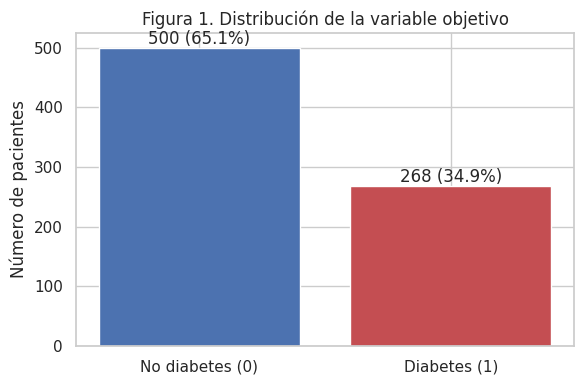

In [6]:
conteo = df["outcome"].value_counts().sort_index()
pct = (conteo / len(df) * 100).round(1)
resultados["clase0"], resultados["clase1"] = int(conteo[0]), int(conteo[1])
resultados["pct_clase1"] = float(pct[1])

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(["No diabetes (0)", "Diabetes (1)"], conteo.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(conteo.values):
    ax.text(i, v + 6, f"{v} ({pct.values[i]}%)", ha="center")
ax.set_title("Figura 1. Distribución de la variable objetivo")
ax.set_ylabel("Número de pacientes")
guardar("fig1_objetivo")

**Interpretación.** Hay 500 pacientes sin diabetes (65.1 %) y 268 con diabetes (34.9 %). El desbalance es moderado (aprox. 2 a 1). Un modelo que predijera siempre "no diabetes" alcanzaría 65.1 % de accuracy sin detectar un solo caso; por eso el accuracy no es suficiente y se usan recall, precision, F1 y AUC. Además, la división entrenamiento/prueba debe ser **estratificada**.

### 4.2 Distribución de las variables según el resultado

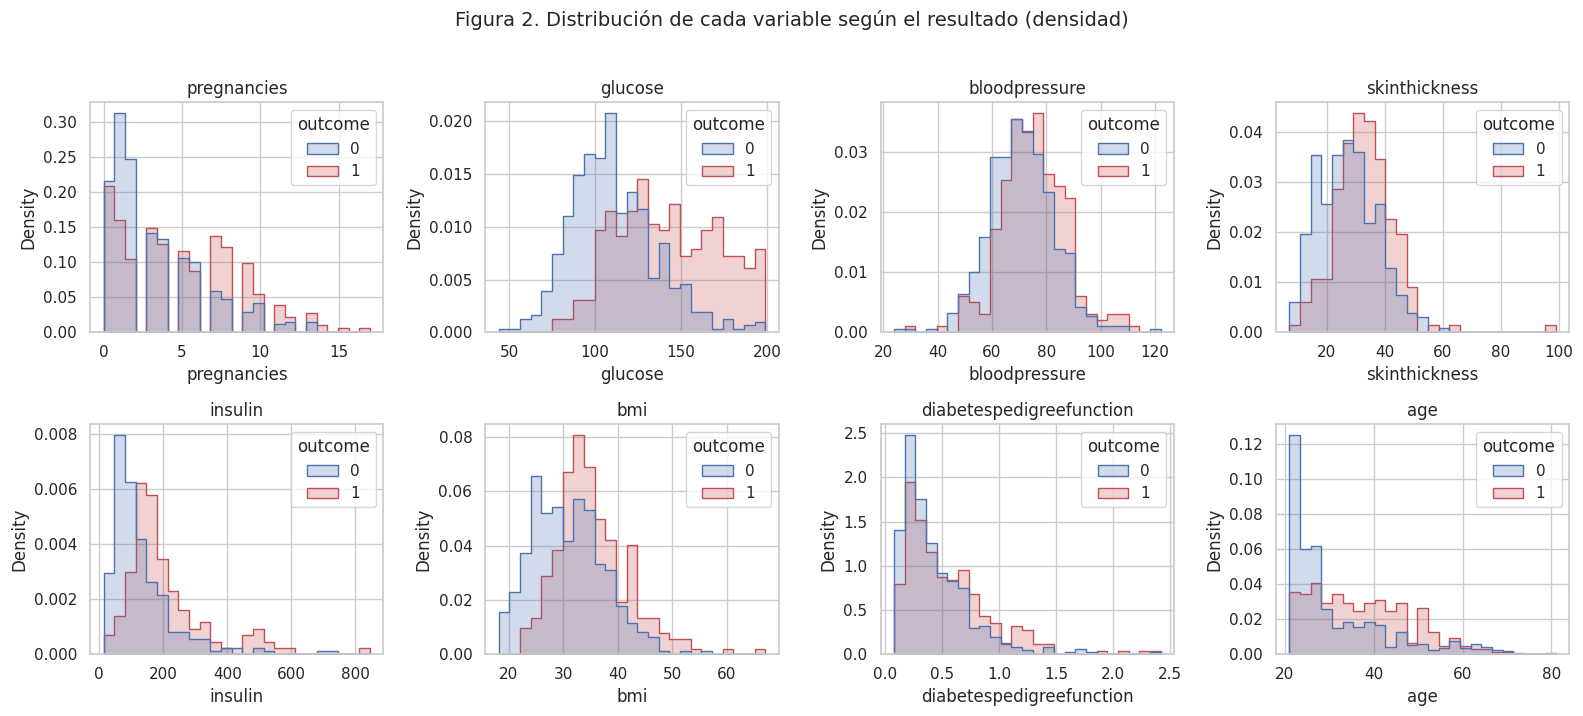

In [7]:
vars_num = [c for c in df.columns if c != "outcome"]
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), vars_num):
    sns.histplot(data=df, x=c, hue="outcome", bins=25, stat="density", common_norm=False,
                 palette=["#4C72B0", "#C44E52"], ax=ax, element="step")
    ax.set_title(c)
    ax.get_legend().set_title("outcome") if ax.get_legend() else None
fig.suptitle("Figura 2. Distribución de cada variable según el resultado (densidad)", y=1.02, fontsize=14)
guardar("fig2_distribuciones")

**Interpretación.** La curva de las pacientes con diabetes (rojo) está desplazada hacia la derecha en `glucose` de forma clara y, en menor grado, en `bmi`, `age`, `insulin` y `pregnancies`. En `bloodpressure` y `diabetespedigreefunction` las distribuciones se superponen mucho. `pregnancies`, `age`, `insulin` y `diabetespedigreefunction` tienen asimetría positiva (cola derecha), lo que explica sus valores atípicos.

### 4.3 Comparación entre grupos: valores promedio y tasas de diabetes por categorías

In [8]:
medias = df.groupby("outcome")[vars_num].mean().round(2).T
medias.columns = ["Media sin diabetes", "Media con diabetes"]
medias["Diferencia relativa (%)"] = ((medias["Media con diabetes"] / medias["Media sin diabetes"] - 1) * 100).round(1)
medias

,Media sin diabetes,Media con diabetes,Diferencia relativa (%)
pregnancies,3.30,4.87,47.6
glucose,110.64,142.32,28.6
bloodpressure,70.88,75.32,6.3
skinthickness,27.24,33.00,21.1
insulin,130.29,206.85,58.8
bmi,30.86,35.41,14.7
diabetespedigreefunction,0.43,0.55,27.9
age,31.19,37.07,18.9


**Interpretación (Tabla 2 del informe).** La mayor diferencia relativa entre grupos se observa en `insulin` (+58.8 %) y `pregnancies` (+47.6 %), seguidas de `glucose` (+28.6 %), `diabetespedigreefunction` (+27.9 %), `skinthickness` (+21.1 %), `age` (+18.9 %) y `bmi` (+14.7 %); `bloodpressure` casi no cambia (+6.3 %). Son asociaciones descriptivas entre grupos. La diferencia relativa depende de la escala de cada variable, por lo que no equivale a la importancia predictiva (ver sección 6.6).

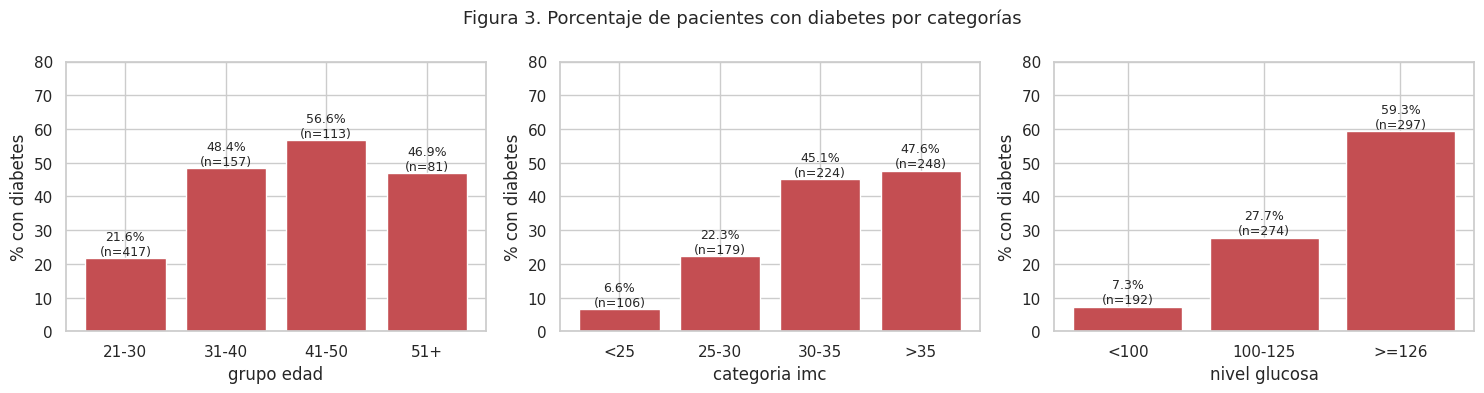

In [9]:
d = df.copy()
d["grupo_edad"] = pd.cut(d["age"], [20, 30, 40, 50, 100], labels=["21-30", "31-40", "41-50", "51+"])
d["categoria_imc"] = pd.cut(d["bmi"], [0, 25, 30, 35, 100], labels=["<25", "25-30", "30-35", ">35"], right=False)
d["nivel_glucosa"] = pd.cut(d["glucose"], [0, 100, 126, 300], labels=["<100", "100-125", ">=126"], right=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
tasas = {}
for ax, c in zip(axes, ["grupo_edad", "categoria_imc", "nivel_glucosa"]):
    t = d.groupby(c, observed=True)["outcome"].agg(["mean", "count"])
    tasas[c] = {str(k): round(float(v), 3) for k, v in t["mean"].items()}
    ax.bar(t.index.astype(str), t["mean"] * 100, color="#C44E52")
    for i, (m, n) in enumerate(zip(t["mean"], t["count"])):
        ax.text(i, m * 100 + 1, f"{m*100:.1f}%\n(n={n})", ha="center", fontsize=9)
    ax.set_ylim(0, 80); ax.set_ylabel("% con diabetes"); ax.set_xlabel(c.replace("_", " "))
fig.suptitle("Figura 3. Porcentaje de pacientes con diabetes por categorías", fontsize=13)
resultados["tasas_categorias"] = tasas
guardar("fig3_tasas")

**Interpretación.** El porcentaje con diabetes crece con la glucosa (7.3 % si <100, 27.7 % entre 100 y 125 y 59.3 % si ≥126), con el IMC (6.6 % si <25 frente a 47.6 % si >35) y con la edad (21.6 % entre 21 y 30 años; 48.4 % a 56.6 % en los grupos de 31 a 50). El grupo de 51+ (46.9 %) no sigue creciendo, aunque tiene pocos registros (n = 81). Estas son asociaciones y no implican causalidad; además, los cortes de las categorías son definidos por el grupo para el análisis.

### 4.4 Valores atípicos: revisión visual

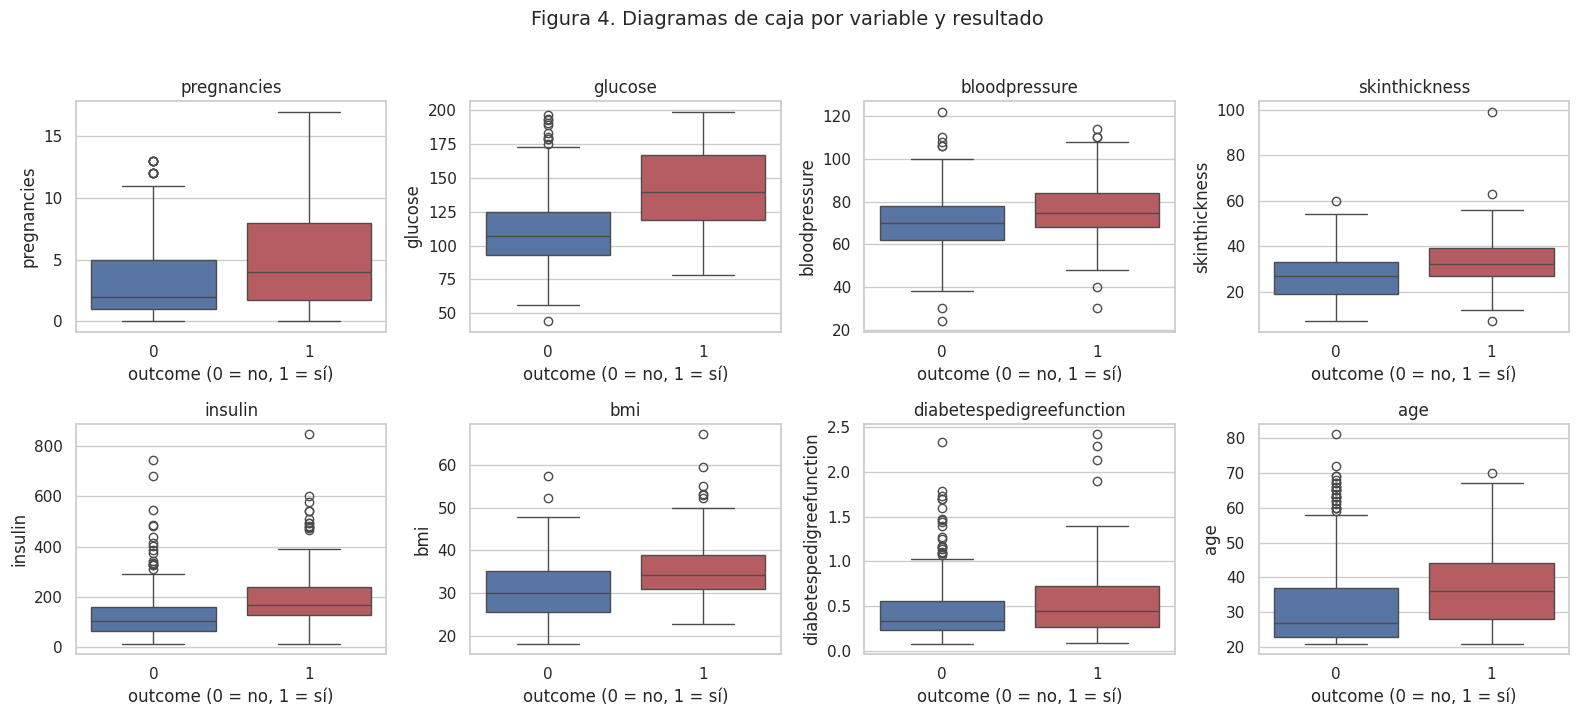

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), vars_num):
    sns.boxplot(data=df, x="outcome", y=c, palette=["#4C72B0", "#C44E52"], ax=ax)
    ax.set_title(c); ax.set_xlabel("outcome (0 = no, 1 = sí)")
fig.suptitle("Figura 4. Diagramas de caja por variable y resultado", y=1.02, fontsize=14)
guardar("fig4_boxplots")

**Interpretación.** Los puntos fuera de los bigotes aparecen sobre todo en `diabetespedigreefunction` (29), `insulin` (24), `bloodpressure` (14), `age` (9) y `bmi` (8), según el conteo IQR de la sección 3.2. Son valores extremos pero posibles, por lo que se conservan (sección 3.2). La mediana de `glucose` es claramente mayor en el grupo con diabetes y las cajas se solapan solo parcialmente (el tercer cuartil sin diabetes, 125, apenas supera al primero con diabetes, 119), lo que anticipa que será la variable más informativa.

### 4.5 Valores faltantes según el resultado

In [11]:
fal_out = df.isnull().groupby(df["outcome"]).mean().T[[0, 1]] * 100
fal_out.columns = ["% faltante (sin diabetes)", "% faltante (con diabetes)"]
fal_out = fal_out.round(1)
resultados["faltante_por_clase"] = fal_out.to_dict()
fal_out.loc[["glucose", "bloodpressure", "skinthickness", "insulin", "bmi"]]

,% faltante (sin diabetes),% faltante (con diabetes)
glucose,0.6,0.7
bloodpressure,3.8,6.0
skinthickness,27.8,32.8
insulin,47.2,51.5
bmi,1.8,0.7


**Interpretación.** El porcentaje de datos no registrados es parecido en ambas clases (p. ej. `insulin`: 47.2 % vs 51.5 %, `skinthickness`: 27.8 % vs 32.8 %), de modo que la ausencia no parece ser una señal fuerte del resultado. Aun así, no se puede descartar que dependa de otros factores no medidos.

### 4.6 Relaciones entre variables y correlaciones

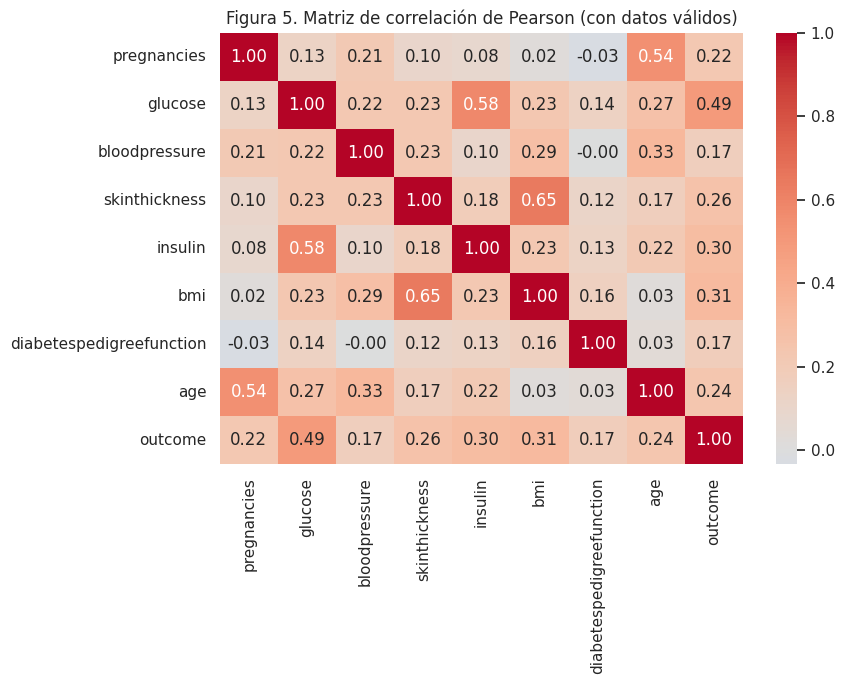

,correlación con outcome
glucose,0.495
bmi,0.314
insulin,0.303
skinthickness,0.259
age,0.238
pregnancies,0.222
diabetespedigreefunction,0.174
bloodpressure,0.171


In [12]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Figura 5. Matriz de correlación de Pearson (con datos válidos)")
guardar("fig5_correlacion")
corr_out = corr["outcome"].drop("outcome").sort_values(ascending=False).round(3)
resultados["corr_outcome"] = corr_out.to_dict()
corr_out.to_frame("correlación con outcome")

**Interpretación.** `glucose` es la variable más asociada con `outcome` (r = 0.495), seguida de `bmi` (0.314), `insulin` (0.303), `skinthickness` (0.259), `age` (0.238) y `pregnancies` (0.222); `diabetespedigreefunction` (0.174) y `bloodpressure` (0.171) tienen asociación débil. Entre predictoras, la correlación más alta es `skinthickness`–`bmi` (0.65), seguida de `insulin`–`glucose` (0.58) y `age`–`pregnancies` (0.54): hay correlación moderada, lo que puede afectar la interpretación de los coeficientes de la regresión logística (multicolinealidad moderada), aunque no es severa. La correlación solo mide relaciones lineales.

### 4.7 Relación entre glucosa e IMC

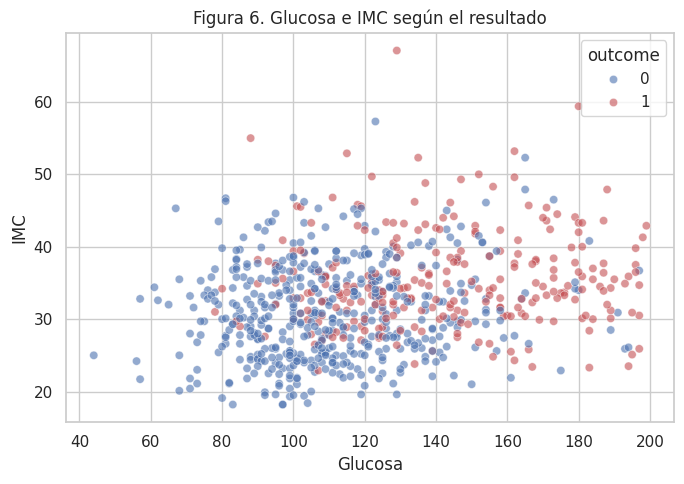

In [13]:
fig, ax = plt.subplots(figsize=(7, 5))
sns.scatterplot(data=df, x="glucose", y="bmi", hue="outcome", palette=["#4C72B0", "#C44E52"], alpha=.6, ax=ax)
ax.set_title("Figura 6. Glucosa e IMC según el resultado")
ax.set_xlabel("Glucosa"); ax.set_ylabel("IMC")
guardar("fig6_glucosa_imc")

**Interpretación.** Los casos con diabetes se concentran en la zona de glucosa alta; con glucosa baja casi todos los puntos son azules sin importar el IMC. En la zona intermedia ambas clases se mezclan, de modo que ninguna recta separa perfectamente los grupos. Esto anticipa un techo de desempeño moderado para cualquier clasificador con estas variables.

### 4.8 Conclusiones del EDA para el modelado
1. Desbalance moderado (34.9 % positivos) → división estratificada, y evaluar con recall/F1/AUC, no solo accuracy.
2. `glucose` es la variable más informativa; `bmi`, `insulin`, `age` y `pregnancies` aportan señal secundaria.
3. Hay muchos datos no registrados en `insulin` y `skinthickness` → imputación dentro del `Pipeline` (sin fuga de información).
4. Los valores atípicos son plausibles → se conservan; los árboles/bosques no necesitan escalamiento, la regresión logística sí.

## 5. Selección y entrenamiento de modelos
Como la tarea es de **clasificación binaria**, se comparan:

| Modelo | Por qué se incluye |
|---|---|
| **Regresión logística** | Modelo lineal simple e interpretable (coeficientes); línea base. |
| **Regresión logística con `class_weight="balanced"`** | Misma idea pero penaliza más los errores en la clase minoritaria (diabetes), pensando en el desbalance. |
| **Árbol de decisión (sin límite de profundidad)** | Modelo interpretable, no lineal; sirve para evidenciar sobreajuste. |
| **Árbol de decisión (`max_depth=4`)** | Versión simplificada y más legible. La profundidad 4 se fijó de antemano como valor de referencia; **no se hizo búsqueda de hiperparámetros**. |
| **Bosque aleatorio (*Random Forest*)** | Método de conjunto; el estado del arte indica que estos métodos suelen superar a modelos individuales. |

No se optimizan hiperparámetros (según lo indicado en la actividad); se usan los valores por defecto de scikit-learn salvo lo señalado.

### 5.1 Separación de predictoras y objetivo, y división entrenamiento/prueba
División **80 % / 20 %**, **estratificada** por `outcome` y con semilla fija (`random_state=42`) para que sea reproducible. El conjunto de prueba no se usa en ninguna decisión de preprocesamiento.

In [14]:
X = df.drop(columns="outcome")
y = df["outcome"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

resumen_split = pd.DataFrame({
    "registros": [len(X_train), len(X_test)],
    "% diabetes": [round(y_train.mean()*100, 1), round(y_test.mean()*100, 1)]
}, index=["Entrenamiento", "Prueba"])
resultados["n_train"], resultados["n_test"] = len(X_train), len(X_test)
resultados["pct_pos_train"], resultados["pct_pos_test"] = float(round(y_train.mean()*100, 1)), float(round(y_test.mean()*100, 1))
resumen_split

,registros,% diabetes
Entrenamiento,614,34.9
Prueba,154,35.1


**Interpretación.** 614 registros para entrenar y 154 para probar, con proporciones de diabetes casi idénticas (34.9 % y 35.1 %) gracias a la estratificación. Con solo 154 pacientes de prueba (54 positivos), las métricas tienen **mucha variabilidad**: unos pocos casos cambian visiblemente un porcentaje. Esto se tiene en cuenta en la comparación.

### 5.2 Preparación de variables y construcción de los modelos
Todas las variables son numéricas. Cada modelo se encapsula en un `Pipeline` que (1) imputa con la mediana **calculada solo con el entrenamiento** y (2) escala con `StandardScaler` solo en la regresión logística (los árboles no lo necesitan).

In [15]:
def crear_pipeline(modelo, escalar):
    pasos = [("imputador", SimpleImputer(strategy="median"))]
    if escalar:
        pasos.append(("escalador", StandardScaler()))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)

modelos = {
    "Regresión logística": crear_pipeline(LogisticRegression(max_iter=1000), True),
    "Regresión logística (balanced)": crear_pipeline(LogisticRegression(max_iter=1000, class_weight="balanced"), True),
    "Árbol de decisión": crear_pipeline(DecisionTreeClassifier(random_state=RANDOM_STATE), False),
    "Árbol de decisión (depth=4)": crear_pipeline(DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE), False),
    "Random Forest": crear_pipeline(RandomForestClassifier(random_state=RANDOM_STATE), False),
}
print("Modelos definidos:", list(modelos))

Modelos definidos: ['Regresión logística', 'Regresión logística (balanced)', 'Árbol de decisión', 'Árbol de decisión (depth=4)', 'Random Forest']


### 5.3 Validación cruzada (solo sobre el entrenamiento)
Se aplica validación cruzada estratificada de 5 pliegues **dentro del conjunto de entrenamiento**. Aporta una estimación del desempeño menos dependiente de una sola partición y permite ver la variabilidad (desviación estándar), sin tocar el conjunto de prueba.

In [16]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]
filas_cv = []
for nombre, pipe in modelos.items():
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring)
    fila = {"Modelo": nombre}
    for m in scoring:
        fila[f"{m} (media)"] = r[f"test_{m}"].mean()
        fila[f"{m} (±sd)"] = r[f"test_{m}"].std()
    filas_cv.append(fila)
tabla_cv = pd.DataFrame(filas_cv).set_index("Modelo")
resultados["cv"] = tabla_cv.round(4).to_dict(orient="index")
tabla_cv_fmt = pd.DataFrame({m: [f"{tabla_cv.loc[n, m + ' (media)']:.3f} ± {tabla_cv.loc[n, m + ' (±sd)']:.3f}" for n in tabla_cv.index]
                             for m in scoring}, index=tabla_cv.index)
tabla_cv_fmt.columns = ["Accuracy", "Precision", "Recall", "F1", "AUC"]
print("Tabla 3. Validación cruzada estratificada de 5 pliegues (media ± desviación estándar)")
tabla_cv_fmt

Tabla 3. Validación cruzada estratificada de 5 pliegues (media ± desviación estándar)


,Accuracy,Precision,Recall,F1,AUC
Modelo,,,,,
Regresión logística,0.788 ± 0.019,0.764 ± 0.060,0.575 ± 0.023,0.655 ± 0.024,0.843 ± 0.019
Regresión logística (balanced),0.762 ± 0.011,0.649 ± 0.026,0.701 ± 0.039,0.672 ± 0.013,0.844 ± 0.016
Árbol de decisión,0.673 ± 0.023,0.531 ± 0.037,0.580 ± 0.050,0.552 ± 0.027,0.651 ± 0.021
Árbol de decisión (depth=4),0.733 ± 0.043,0.647 ± 0.078,0.542 ± 0.079,0.585 ± 0.060,0.788 ± 0.028
Random Forest,0.761 ± 0.019,0.690 ± 0.042,0.575 ± 0.038,0.626 ± 0.027,0.816 ± 0.022


**Interpretación (Tabla 3 del informe).** La regresión logística con pesos balanceados logra el mayor recall (0.701) con un F1 y un AUC entre los más altos (0.672 y 0.844); la regresión logística estándar alcanza el mayor accuracy (0.788) pero con recall de solo 0.575, es decir, acierta más en la clase mayoritaria. El árbol sin límite es el más débil (AUC 0.651). Las desviaciones estándar muestran que el recall del árbol de profundidad 4 es el más inestable entre pliegues (±0.079), mientras que el AUC de las regresiones logísticas es el más estable (±0.016 a ±0.019).

### 5.4 Entrenamiento final y predicciones sobre el conjunto de prueba

In [17]:
pred, proba, filas_test, filas_gap = {}, {}, [], []
for nombre, pipe in modelos.items():
    pipe.fit(X_train, y_train)
    pred[nombre] = pipe.predict(X_test)
    proba[nombre] = pipe.predict_proba(X_test)[:, 1]
    filas_test.append({
        "Modelo": nombre,
        "Accuracy": accuracy_score(y_test, pred[nombre]),
        "Precision": precision_score(y_test, pred[nombre]),
        "Recall": recall_score(y_test, pred[nombre]),
        "F1": f1_score(y_test, pred[nombre]),
        "ROC-AUC": roc_auc_score(y_test, proba[nombre]),
    })
    filas_gap.append({"Modelo": nombre,
        "Accuracy entrenamiento": pipe.score(X_train, y_train),
        "Accuracy prueba": accuracy_score(y_test, pred[nombre])})
tabla_test = pd.DataFrame(filas_test).set_index("Modelo")
tabla_gap = pd.DataFrame(filas_gap).set_index("Modelo")
tabla_gap["Diferencia"] = tabla_gap["Accuracy entrenamiento"] - tabla_gap["Accuracy prueba"]
resultados["test"] = tabla_test.round(4).to_dict(orient="index")
resultados["gap"] = tabla_gap.round(4).to_dict(orient="index")
display(tabla_test.round(3))
display(tabla_gap.round(3))

,Accuracy,Precision,Recall,F1,ROC-AUC
Modelo,,,,,
Regresión logística,0.708,0.600,0.500,0.545,0.813
Regresión logística (balanced),0.734,0.603,0.704,0.650,0.813
Árbol de decisión,0.682,0.553,0.481,0.515,0.636
Árbol de decisión (depth=4),0.786,0.698,0.685,0.692,0.789
Random Forest,0.766,0.696,0.593,0.640,0.821


,Accuracy entrenamiento,Accuracy prueba,Diferencia
Modelo,,,
Regresión logística,0.796,0.708,0.089
Regresión logística (balanced),0.759,0.734,0.025
Árbol de decisión,1.000,0.682,0.318
Árbol de decisión (depth=4),0.795,0.786,0.009
Random Forest,1.000,0.766,0.234


**Interpretación (Tablas 4 y 7 del informe).** En prueba, la regresión logística balanceada tiene el mayor recall (0.704), el árbol de profundidad 4 el mayor accuracy y F1 (0.786 y 0.692) y el Random Forest el mayor AUC (0.821). El árbol sin límite y el Random Forest llegan a 1.000 de accuracy en entrenamiento, evidencia de sobreajuste (diferencias de 0.318 y 0.234 frente a prueba). La sección 6 analiza los errores con las matrices de confusión.

## 6. Evaluación e interpretación

### 6.1 Matrices de confusión (conjunto de prueba)

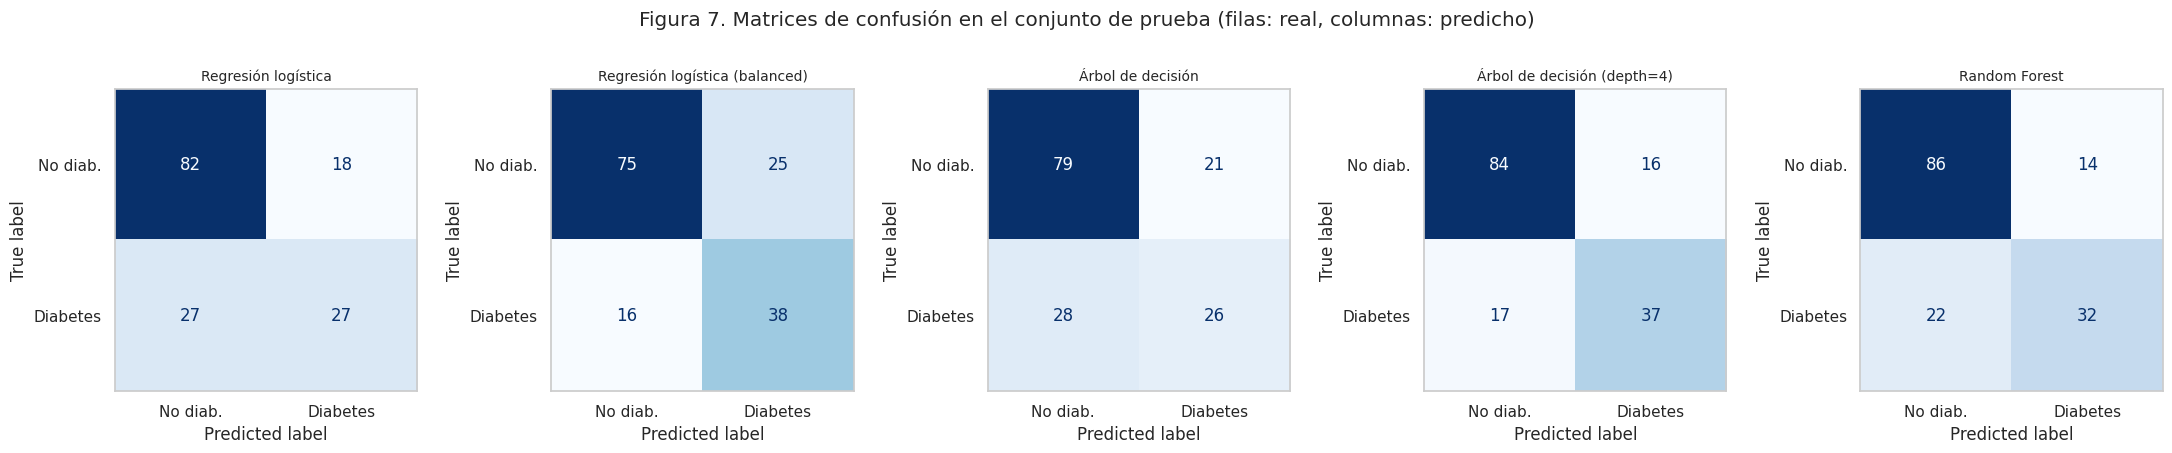

,VN,FP,FN,VP
Regresión logística,82,18,27,27
Regresión logística (balanced),75,25,16,38
Árbol de decisión,79,21,28,26
Árbol de decisión (depth=4),84,16,17,37
Random Forest,86,14,22,32


In [18]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4.2))
cms = {}
for ax, (nombre, p) in zip(axes, pred.items()):
    cm = confusion_matrix(y_test, p)
    cms[nombre] = cm.tolist()
    ConfusionMatrixDisplay(cm, display_labels=["No diab.", "Diabetes"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(nombre, fontsize=10)
    ax.grid(False)
fig.suptitle("Figura 7. Matrices de confusión en el conjunto de prueba (filas: real, columnas: predicho)", y=1.04)
resultados["confusion"] = cms
guardar("fig7_confusion")
pd.DataFrame({n: {"VN": c[0][0], "FP": c[0][1], "FN": c[1][0], "VP": c[1][1]} for n, c in cms.items()}).T

**Interpretación.** *VN* = verdaderos negativos, *FP* = falsos positivos (se predijo diabetes pero no la tenía), *FN* = falsos negativos (se predijo no diabetes pero sí la tenía), *VP* = verdaderos positivos.

- **Regresión logística:** 82 VN, 18 FP, 27 FN, 27 VP. Es conservadora: acierta bastante en la clase negativa pero **deja pasar la mitad de los casos de diabetes** (27 de 54).
- **Regresión logística (balanced):** 75 VN, 25 FP, 16 FN, 38 VP. Detecta más casos reales (38 de 54) a costa de más falsos positivos (25 frente a 18); es el modelo con menos falsos negativos junto con el árbol de profundidad 4 (17).
- **Árbol sin límite:** 79 VN, 21 FP, 28 FN, 26 VP; es el peor, con la mayor cantidad de falsos negativos (28).
- **Árbol (depth=4):** 84 VN, 16 FP, 17 FN, 37 VP; en esta partición logra el mejor equilibrio.
- **Random Forest:** 86 VN, 14 FP, 22 FN, 32 VP; el menor número de falsos positivos (14) pero 22 casos de diabetes sin detectar.

**Qué error es más grave.** En un contexto de tamizaje, un falso negativo (no detectar a una paciente con diabetes) es más costoso que un falso positivo, porque el falso positivo se resuelve con una prueba confirmatoria, mientras que el falso negativo retrasa el diagnóstico. Por eso se da prioridad al **recall de la clase 1** sin ignorar la precisión.

### 6.2 Métricas por clase (reporte de clasificación)

In [19]:
reportes = {}
for nombre, p in pred.items():
    rep = classification_report(y_test, p, target_names=["No diabetes", "Diabetes"], output_dict=True)
    reportes[nombre] = {k: {m: round(v, 3) for m, v in rep[k].items()} for k in ["No diabetes", "Diabetes"]}
    print("="*60, "\n", nombre, "\n", classification_report(y_test, p, target_names=["No diabetes", "Diabetes"], digits=3))
resultados["reportes"] = reportes

 Regresión logística 
               precision    recall  f1-score   support

 No diabetes      0.752     0.820     0.785       100
    Diabetes      0.600     0.500     0.545        54

    accuracy                          0.708       154
   macro avg      0.676     0.660     0.665       154
weighted avg      0.699     0.708     0.701       154

 Regresión logística (balanced) 
               precision    recall  f1-score   support

 No diabetes      0.824     0.750     0.785       100
    Diabetes      0.603     0.704     0.650        54

    accuracy                          0.734       154
   macro avg      0.714     0.727     0.717       154
weighted avg      0.747     0.734     0.738       154

 Árbol de decisión 
               precision    recall  f1-score   support

 No diabetes      0.738     0.790     0.763       100
    Diabetes      0.553     0.481     0.515        54

    accuracy                          0.682       154
   macro avg      0.646     0.636     0.639       

**Interpretación.** En todos los modelos la clase "No diabetes" obtiene mejor recall y F1 que "Diabetes", lo que es esperable por tener más ejemplos. La clase de interés (diabetes) es la más difícil: sus F1 van de 0.515 (árbol sin límite) a 0.692 (árbol depth=4).

### 6.3 Curvas ROC

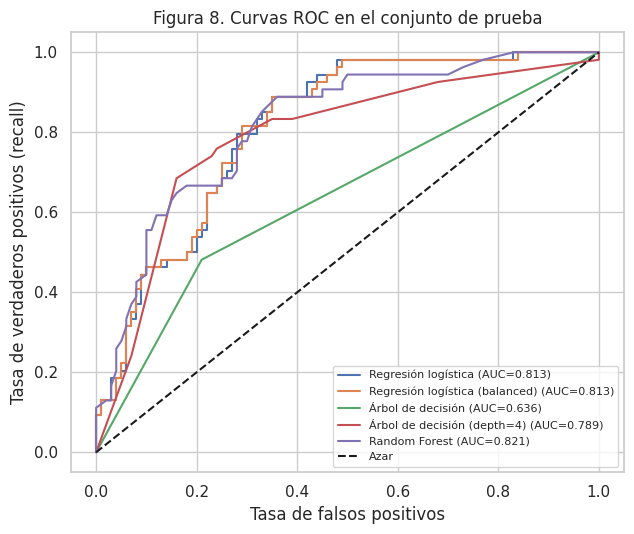

In [20]:
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for nombre in modelos:
    fpr, tpr, _ = roc_curve(y_test, proba[nombre])
    ax.plot(fpr, tpr, label=f"{nombre} (AUC={roc_auc_score(y_test, proba[nombre]):.3f})")
ax.plot([0, 1], [0, 1], "k--", label="Azar")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Figura 8. Curvas ROC en el conjunto de prueba"); ax.legend(fontsize=8)
guardar("fig8_roc")

**Interpretación.** El AUC mide qué tan bien el modelo ordena las pacientes por riesgo, independientemente del umbral de 0.5. Los más altos son Random Forest (0.821) y las regresiones logísticas (0.813), por encima de los árboles (0.789 con depth=4 y 0.636 sin límite). La diferencia entre el árbol sin límite y el resto es grande; las diferencias entre regresión logística y Random Forest son pequeñas.

### 6.4 Comparación entrenamiento vs. prueba y validación cruzada
Se revisa el sobreajuste con la Tabla de accuracy entrenamiento/prueba (sección 5.4) y con la validación cruzada (sección 5.3).

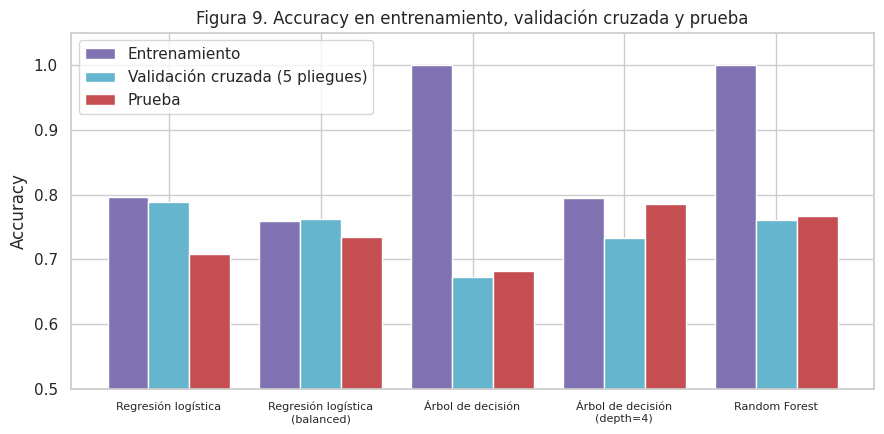

In [21]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(modelos)); w = 0.27
ax.bar(x - w, tabla_gap["Accuracy entrenamiento"], w, label="Entrenamiento", color="#8172B2")
ax.bar(x, tabla_cv["accuracy (media)"], w, label="Validación cruzada (5 pliegues)", color="#64B5CD")
ax.bar(x + w, tabla_gap["Accuracy prueba"], w, label="Prueba", color="#C44E52")
ax.set_xticks(x); ax.set_xticklabels([n.replace(" (", "\n(") for n in modelos], fontsize=8)
ax.set_ylim(0.5, 1.05); ax.set_ylabel("Accuracy"); ax.legend()
ax.set_title("Figura 9. Accuracy en entrenamiento, validación cruzada y prueba")
guardar("fig9_gap")

**Interpretación.**
- El **árbol sin límite** y el **Random Forest** alcanzan 100 % en entrenamiento pero mucho menos en validación/prueba: memorizan los datos (sobreajuste). El árbol sin límite es el caso más grave (validación cruzada 67.3 %, AUC-CV 0.651).
- Las **regresiones logísticas** tienen accuracy de entrenamiento (79.6 % y 75.9 %) similar al de la validación cruzada (78.8 % y 76.2 %): generalizan de forma estable.
- **Importante:** en el conjunto de prueba la regresión logística (70.8 %) queda por debajo de su validación cruzada (78.8 %), y el árbol depth=4 queda por encima (78.6 % frente a 73.3 %). Con 154 pacientes esas diferencias (de 5 a 8 puntos) corresponden a pocos casos y sugiere que **una sola partición es ruidosa**; por eso la selección no se basa únicamente en la prueba, sino en la validación cruzada junto con la prueba.

### 6.5 Tabla comparativa y selección del modelo

In [22]:
comparativa = pd.DataFrame({
    "Recall CV": tabla_cv["recall (media)"],
    "F1 CV": tabla_cv["f1 (media)"],
    "AUC CV": tabla_cv["roc_auc (media)"],
    "Recall prueba": tabla_test["Recall"],
    "F1 prueba": tabla_test["F1"],
    "AUC prueba": tabla_test["ROC-AUC"],
    "Acc. entren. - prueba": tabla_gap["Diferencia"],
}).round(3)
comparativa

,Recall CV,F1 CV,AUC CV,Recall prueba,F1 prueba,AUC prueba,Acc. entren. - prueba
Modelo,,,,,,,
Regresión logística,0.575,0.655,0.843,0.500,0.545,0.813,0.089
Regresión logística (balanced),0.701,0.672,0.844,0.704,0.650,0.813,0.025
Árbol de decisión,0.580,0.552,0.651,0.481,0.515,0.636,0.318
Árbol de decisión (depth=4),0.542,0.585,0.788,0.685,0.692,0.789,0.009
Random Forest,0.575,0.626,0.816,0.593,0.640,0.821,0.234


**Selección.** Se compara con varias evidencias, no solo con el accuracy:

- **Regresión logística (balanced)**: mayor recall en prueba (0.704) y en validación cruzada (0.701), F1 de validación cruzada más alto (0.672), AUC-CV de 0.844 (el más alto junto con la regresión logística estándar, 0.843), brecha pequeña entre entrenamiento y prueba y es **interpretable** por sus coeficientes. Es la mejor opción si se prioriza no dejar pasar casos de diabetes.
- **Árbol depth=4**: tiene el mejor F1 en prueba (0.692) y el mejor accuracy (0.786), pero su desempeño en validación cruzada es menor (accuracy 0.733, recall 0.542, AUC 0.788), por lo que su buen resultado en prueba puede deberse a la partición. Es el mejor candidato como **modelo explicable alternativo**.
- **Random Forest**: AUC en prueba más alto (0.821) y menos falsos positivos, pero recall bajo (0.593 en prueba) y sobreajuste (100 % en entrenamiento).
- **Regresión logística estándar**: buen AUC pero recall en prueba de solo 0.500.
- **Árbol sin límite**: descartado por sobreajuste y bajo AUC.

**Modelo preliminar elegido: regresión logística con `class_weight="balanced"`.** Aún no se ha optimizado ningún hiperparámetro ni el umbral de decisión, y la diferencia frente a otros modelos no es concluyente dado el tamaño de la prueba; eso queda como trabajo para el siguiente corte.

### 6.6 Interpretación del modelo: qué variables pesan más

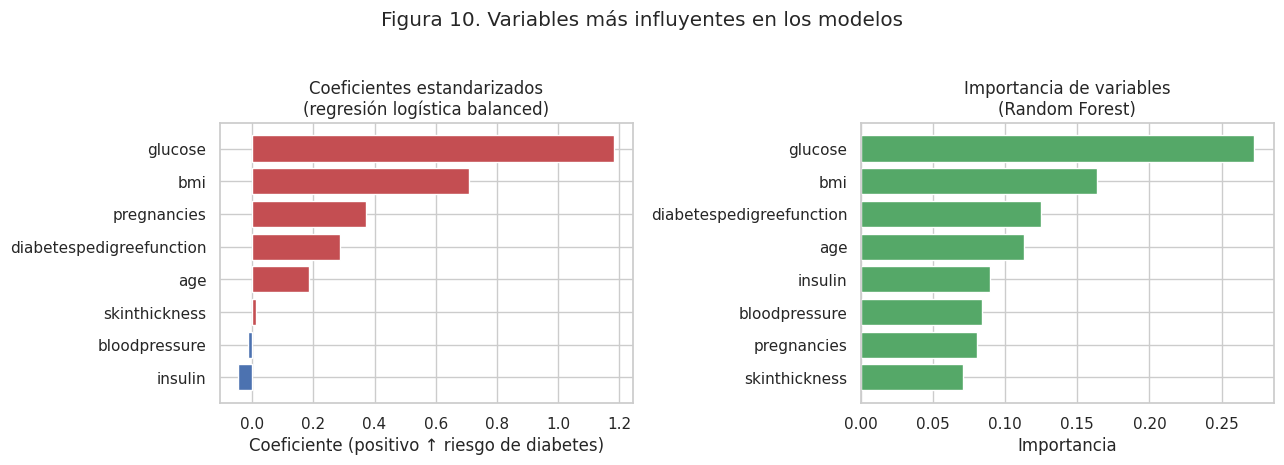

,coef_LR_balanced,importancia_RF
glucose,1.183,0.273
bmi,0.710,0.164
pregnancies,0.373,0.081
diabetespedigreefunction,0.288,0.125
age,0.186,0.113
skinthickness,0.014,0.071
bloodpressure,-0.015,0.084
insulin,-0.045,0.089


In [23]:
lr = modelos["Regresión logística (balanced)"].named_steps["modelo"]
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()
rf = modelos["Random Forest"].named_steps["modelo"]
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].barh(coef.index, coef.values, color=["#C44E52" if v > 0 else "#4C72B0" for v in coef.values])
axes[0].set_title("Coeficientes estandarizados\n(regresión logística balanced)")
axes[0].set_xlabel("Coeficiente (positivo ↑ riesgo de diabetes)")
axes[1].barh(imp.index, imp.values, color="#55A868")
axes[1].set_title("Importancia de variables\n(Random Forest)")
axes[1].set_xlabel("Importancia")
fig.suptitle("Figura 10. Variables más influyentes en los modelos", y=1.03)
resultados["coef_lr"] = coef.round(3).to_dict()
resultados["imp_rf"] = imp.round(3).to_dict()
guardar("fig10_importancias")
pd.DataFrame({"coef_LR_balanced": coef.round(3), "importancia_RF": imp.round(3)}).sort_values("coef_LR_balanced", ascending=False)

**Interpretación.** En ambos modelos `glucose` es la variable más influyente, lo que coincide con el EDA (correlación 0.495). Después aparecen `bmi` y, según el modelo, `diabetespedigreefunction`, `pregnancies` y `age`. Los coeficientes de la regresión logística reflejan **asociación dentro del modelo**, no un efecto causal; y con variables parcialmente correlacionadas (p. ej. `age` y `pregnancies`) deben leerse con cautela.

### 6.7 Árbol de decisión de profundidad 4 (modelo explicable)

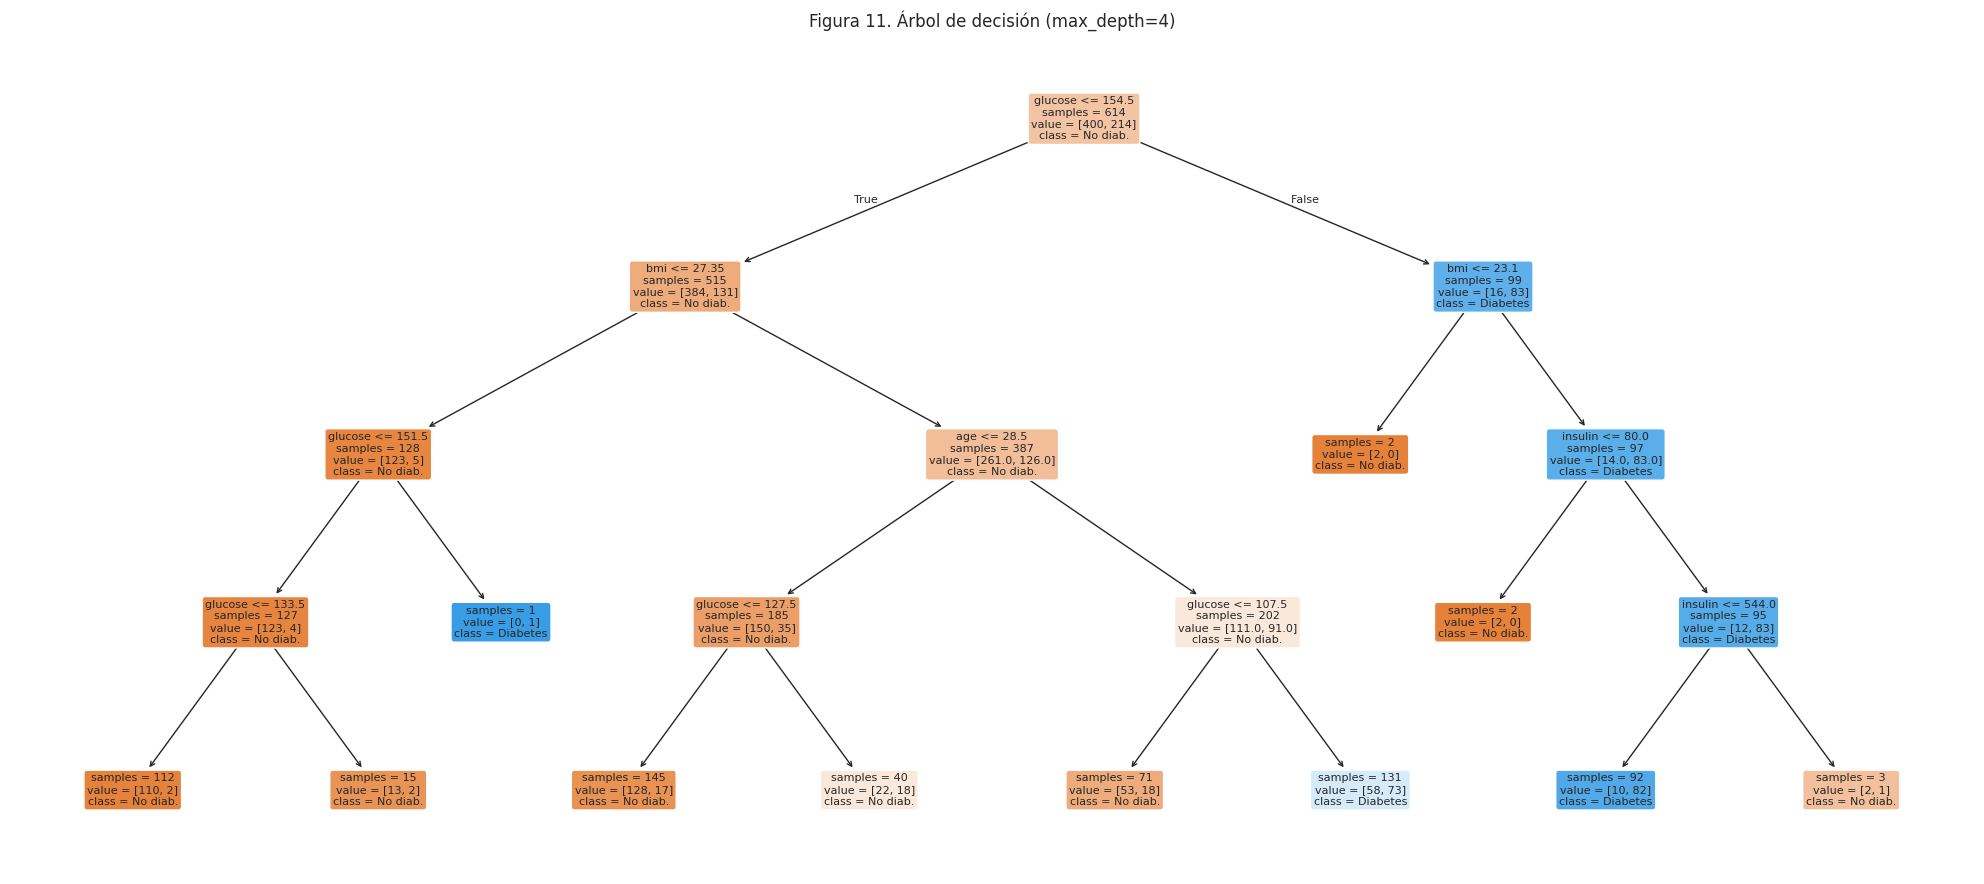

In [24]:
arbol = modelos["Árbol de decisión (depth=4)"].named_steps["modelo"]
fig, ax = plt.subplots(figsize=(20, 9))
plot_tree(arbol, feature_names=X.columns, class_names=["No diab.", "Diabetes"], filled=True, rounded=True, fontsize=8, ax=ax, impurity=False)
ax.set_title("Figura 11. Árbol de decisión (max_depth=4)")
guardar("fig11_arbol")

**Interpretación.** La primera división del árbol se hace sobre `glucose`, lo que confirma su papel dominante; las siguientes usan `bmi`, `age` e `insulin`. Permite explicar una predicción como una secuencia de reglas, lo cual es una ventaja frente al bosque aleatorio, aunque su estabilidad es menor.

## 7. Conclusiones del notebook

**¿Cuáles fueron los principales hallazgos del EDA?**
El dataset tiene 768 pacientes con 34.9 % de casos positivos (desbalance moderado). `glucose` es la variable más asociada con la diabetes (r = 0.495), seguida de `bmi`, `insulin`, `skinthickness`, `age` y `pregnancies`. El porcentaje de diabetes aumenta con la glucosa, el IMC y la edad (hasta los 50 años). Hay muchos datos no registrados (ceros) en `insulin` (48.7 %) y `skinthickness` (29.6 %), y los valores atípicos son clínicamente plausibles.

**¿Qué modelo o solución produjo los resultados más adecuados?**
La **regresión logística con `class_weight="balanced"`** fue la más adecuada para el objetivo de detección: recall de 0.704 en prueba (38 de 54 casos detectados), F1 de validación cruzada de 0.672 y AUC de 0.813 en prueba (0.844 en validación cruzada), con poco sobreajuste y buena interpretabilidad.

**¿Qué evidencias respaldan esa selección?**
Validación cruzada de 5 pliegues, métricas en prueba (accuracy, precision, recall, F1, AUC), matrices de confusión (menor número de falsos negativos de los cinco modelos: 16, frente a 17 del árbol depth=4), comparación entrenamiento vs. prueba y coherencia de las variables importantes con el EDA.

**¿Qué errores o limitaciones se identificaron?**
1. Aun el mejor modelo deja sin detectar 16 de 54 casos de diabetes (29.6 %) y produce 25 falsos positivos.
2. El conjunto de prueba es pequeño (154 registros), por lo que las métricas son inestables; la brecha entre validación cruzada y prueba de varios modelos lo evidencia.
3. La imputación por mediana en `insulin` y `skinthickness` (muchos datos no registrados) puede distorsionar la relación con el resultado.
4. El dataset incluye solo mujeres Pima de 21 años o más; los resultados no son generalizables a otras poblaciones.
5. No se optimizaron hiperparámetros ni el umbral de clasificación; el modelo es preliminar.
6. Los hallazgos son asociaciones, no relaciones causales, y el modelo no sustituye un diagnóstico médico.

## 8. Declaración y evaluación del uso de inteligencia artificial

### 8.1 Uso en el primer avance (conservado)
| Elemento | Información |
|---|---|
| **Herramienta utilizada** | ChatGPT / Claude (según el registro del grupo en el primer avance). |
| **Propósito** | Estructurar el notebook del primer avance y orientar el tratamiento de los ceros del dataset. |
| **Prompt (instrucción completa)** | (1) «Ayúdame a estructurar un notebook en Python para la primera entrega de un proyecto de minería de datos en salud, usando el dataset Pima Indians Diabetes. Debe incluir descripción del dataset, exploración inicial, diagnóstico de calidad, limpieza básica y al menos 3 visualizaciones con interpretación.»<br>(2) «Sugiéreme cómo identificar y tratar los valores en cero en las columnas clínicas (glucosa, presión arterial, insulina, espesor cutáneo, IMC) que probablemente representan datos faltantes.» |
| **Problemas identificados** | La imputación por mediana propuesta se aplicaba sobre todo el conjunto de datos, lo que genera fuga de información al dividir luego en entrenamiento y prueba. |
| **Ajustes realizados** | La imputación se movió a un Pipeline ajustado solo con los datos de entrenamiento (cambio 1 de este notebook). |
| **Decisión final** | Se conservó la estructura del primer avance y la identificación de los ceros imposibles; se descartó la imputación previa a la división. |

### 8.2 Uso 1 en el segundo avance: generación del borrador
| Elemento | Información |
|---|---|
| **Herramienta utilizada** | Claude (Anthropic), en interfaz de chat con ejecución de código (conversación previa a la revisión del Uso 2). |
| **Propósito** | Generar el borrador del notebook de EDA y modelado y del informe del segundo avance a partir del enunciado, del informe y notebook del primer avance y del archivo diabetes.csv. |
| **Prompt (instrucción completa)** | Instrucción formulada en el chat, presentada con redacción formal y conservando su contenido: «Elabora el segundo avance del proyecto (notebook y informe) siguiendo las indicaciones de la actividad y dando continuidad al primer avance.» (adjuntos: enunciado del avance 2, informe y notebook del avance 1 y diabetes.csv). |
| **Problemas identificados** | (1) Corrigió por iniciativa propia la fuga de información del primer avance; no se le pidió.<br>(2) Incluyó cinco modelos cuando la actividad exige al menos dos.<br>(3) Reutilizó las referencias del primer avance sin verificar los DOI ni lo que se atribuye a cada trabajo.<br>(4) Redactó interpretaciones con cifras de ejecuciones previas; al auditarlas se hallaron las inconsistencias descritas en el Uso 2.<br>(5) Dejó textos de borrador y secciones por completar. |
| **Ajustes realizados** | Las inconsistencias se corrigieron en el Uso 2 (ver abajo). Se eliminaron los textos de borrador. |
| **Decisión final** | Se conservó la estructura general, los cinco modelos (permiten comparar un modelo lineal, un árbol y un método de conjunto), la corrección del Pipeline y el criterio de priorizar el recall de la clase positiva. No se conservó ninguna afirmación que no pudiera contrastarse con las salidas del notebook. |

### 8.3 Uso 2 en el segundo avance: auditoría, verificación y corrección
| Elemento | Información |
|---|---|
| **Herramienta utilizada** | Claude Sonnet 5.5 (Anthropic), en interfaz de chat con ejecución de código. |
| **Propósito** | Auditar el informe y el notebook contra la rúbrica; volver a ejecutar el notebook para contrastar cada cifra del informe; corregir los errores encontrados; reconstruir el informe en PDF con las tablas y figuras generadas por el notebook; redactar esta declaración. |
| **Prompt (instrucción completa)** | Instrucciones formuladas en el chat, presentadas con redacción formal y conservando su contenido:<br>(1) «Ayúdame a analizar la rúbrica del segundo avance del proyecto de aula de Minería de Datos, identificando entregables, criterios de evaluación y puntos críticos, sin resolverla todavía.» (adjunto: enunciado del avance 2).<br>(2) «Revisa el informe del segundo avance elaborado por mis compañeros junto con el notebook del primer avance, y verifica su coherencia con lo que pide la actividad.» (adjuntos: informe del avance 2 y notebook del avance 1).<br>(3) «Confirma si hace falta el notebook del segundo avance para completar la entrega.»<br>(4) «Revisa el notebook del segundo avance y contrástalo con el informe.» (adjunto: notebook del avance 2).<br>(5) «Realiza todas las correcciones necesarias para que el notebook y el informe cumplan con la rúbrica, verifica el cumplimiento de cada criterio, redacta la sección de declaración y evaluación del uso de inteligencia artificial e indica específicamente qué contenido incluiste en ella.» |
| **Problemas identificados** | (1) Con su búsqueda web solo pudo confirmar la existencia de una de las cinco referencias del estado del arte (Arrubla-Hoyos et al., localizada en el repositorio institucional de la CUC); las otras cuatro no pudo confirmarlas ni descartarlas.<br>(2) No disponía del diabetes.csv del grupo: usó una copia pública del dataset Pima (repositorio de J. Brownlee en GitHub). Coincidieron 768 registros, 500/268 casos por clase, los 374 y 227 ceros en insulina y espesor cutáneo, y las matrices de confusión de los cinco modelos con las del notebook del grupo.<br>(3) No puede verificar que el grupo comprenda el contenido ni cómo trabajó realmente.<br>(4) Añadió tildes a los nombres de los integrantes y desconoce sus segundos apellidos. |
| **Ajustes realizados** | Errores detectados y corregidos:<br>(a) la Tabla 3 del informe mostraba desviaciones estándar de accuracy y F1 que no aparecían en ninguna salida del notebook; ahora el notebook imprime media ± desviación de accuracy, precision, recall, F1 y AUC, y el informe copia esa tabla.<br>(b) La sección 3.2 afirmaba que el escalamiento mitiga los atípicos en la regresión logística; es incorrecto, y se reescribió como limitación.<br>(c) La sección 4.4 decía que las cajas de glucosa «casi no se solapan»; el tercer cuartil sin diabetes (125) supera al primero con diabetes (119), por lo que se solapan parcialmente.<br>(d) La sección 4.6 omitía la correlación más alta entre predictoras (skinthickness–bmi, 0.65).<br>(e) Tres valores de la Tabla 3 del informe no coincidían con el notebook: el F1 de la regresión logística (0.654 frente a 0.655), la desviación de su AUC (0.018 frente a 0.019) y la desviación del recall de la regresión balanceada (0.040 frente a 0.039).<br>(f) Las figuras del informe tenían numeración distinta a las del notebook; ahora coinciden (Figuras 1 a 11) y se añadieron las que solo estaban en el notebook.<br>(g) El estado del arte se reescribió para no atribuir a los trabajos citados resultados que no pudieron verificarse; solo se describe lo que se desprende de cada título (y, para Arrubla-Hoyos et al., su resumen).<br>(h) Se añadió interpretación a la tabla de validación cruzada del notebook.<br>(i) Se eliminaron los textos de borrador del notebook y del informe. |
| **Decisión final** | Se conservó todo el contenido técnico no listado arriba, porque se verificó cifra por cifra con la re-ejecución. Quedan a cargo del grupo: abrir los cinco DOI y confirmar que existen y que el resumen coincide con lo descrito, completar nombres y apellidos si aplica, y volver a ejecutar el notebook con su propio diabetes.csv. |

### 8.4 Evaluación crítica global
- **¿Respondió exactamente lo solicitado?** En gran parte sí. Con los prompts formulados anteriormente, la IA respondió de forma distinta según la precisión de cada instrucción. En el Uso 1, una única instrucción general («elabora el segundo avance…») llevó a tomar decisiones que no se pidieron (cinco modelos en lugar de dos y la corrección de la fuga de información); todas se revisaron y se conservaron de forma justificada. En el Uso 2, las cinco instrucciones, más acotadas, se atendieron por etapas: primero se analizó la rúbrica sin resolverla, luego se revisaron el informe y el notebook del primer avance, se identificó que faltaba el notebook del segundo avance y, con este, se hicieron las correcciones, la verificación de cumplimiento y la declaración, indicando qué se incluyó en ella. La única solicitud que no pudo cumplirse por completo fue verificar que todas las referencias existan, pues solo se confirmó una; esa comprobación queda a cargo del grupo.
- **¿Usó columnas y datos reales?** Sí. Las ocho variables y el objetivo existen en el dataset y todas las cifras del informe se contrastaron con la re-ejecución del notebook.
- **¿Inventó métricas o referencias?** No se detectaron métricas inventadas; sí varias cifras o afirmaciones inconsistentes con el notebook (ver ajustes a-e). Las referencias se reutilizaron del primer avance sin verificar; el contenido atribuido a ellas se limitó a lo comprobable.
- **¿Entregó más información de la pedida?** Sí: cinco modelos en lugar de dos, curvas ROC, importancia de variables y árbol de profundidad 4. Se conservó porque aporta a la comparación crítica; no se agregó optimización de hiperparámetros, que la actividad no pide.
- **¿Omitió elementos?** Omitió la correlación skinthickness–bmi, las desviaciones estándar en el notebook y una interpretación de la validación cruzada; se añadieron.
- **¿El código funcionó?** Sí. Las 25 celdas de código se ejecutan en orden y sin errores, y reproducen las matrices de confusión originales.
- **¿La interpretación coincide con las salidas?** Tras las correcciones, sí: Tablas 1 a 7, matrices de confusión, métricas por clase, coeficientes e importancias del informe se generan desde la misma ejecución del notebook.

### Declaración de responsabilidad
Como integrantes del grupo declaramos que revisamos y verificamos el contenido generado con apoyo de herramientas de inteligencia artificial. Consideramos que las partes utilizadas responden a lo solicitado y son coherentes con los datos y resultados obtenidos. Identificamos y corregimos los errores, excesos, omisiones o posibles alucinaciones encontradas. Comprendemos el contenido presentado y asumimos la responsabilidad académica por la totalidad del notebook y del informe entregados.

In [25]:
with open("results.json", "w") as f:
    json.dump(resultados, f, indent=2, ensure_ascii=False, default=float)
print("Resultados guardados en results.json")

Resultados guardados en results.json
